# AP 155 Lab Exercise
---
## Exercise 9: Minimization

_Instructions_: 
- **Problem 1**
    - Figure: Generate a $1\times2$ showing the two functions and minima markings solved using golden-search
    - Discussion: What happens if a number other than the golden ratio is used to perform the golden section search algorithm? What did you have to do to obtain the maximum?
- **Problem 2**
    - Figure: Plot of $U$ vs $N$ (for a minimum of 20 $N$ points). Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - Discussion: In a single sentence, describe what gradient descent does. How does the parameter $\gamma$ matter? 
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Sinadjan, Joseph Daniel 
- _Student No._: 2024-13266
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="golden.png" alt="Alt text" width=45%> <img src="config.png" alt="Alt text" width=45%>



### Report discussion

#### Problem 1

We found the extrema of the given function using golden search after calculating the analytic derivative. The golden search function implementation was provided ahead of time. The challenge was to implement it in on the given function. Verifying that all extrema were found was done via online graph

#### Problem 2 


### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [177]:
import numpy as np
import matplotlib.pyplot as plt
import math

rng = np.random.default_rng(24601)

### Problem 1: Min-maxxing with golden-search

Consider the following equation,

$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4. \tag{1}
$$

- Plot $\phi$ across some domain $x$ (you choose the domain). Visually inspect the plot and record initial estimates for all local minima and local maxima within the interval.
- Implement the Golden-Section Search algorithm (see Section $3$, you may copy it into your code below) to find function minima within a given bracket $[a, b]$ to a specified tolerance. Use your algorithm to locate the precise coordinates $(x^*, \phi(x^*))$ of all local minima and local maxima of Eq. $(1)$.
- **[REPORT FIGURE 1]** Generate a single figure containing a $1 \times 2$ array of subplots:
    - Left Subplot: Plot $\phi(x)$ versus $x$. Overlay and label all identified local minima and maxima using distinct markers.
    - Right Subplot: Plot the analytical first derivative $\phi'(x)$ versus $x$. Mark the zero-crossing points that correspond to the extrema found on the left plot.

In [65]:
# add the `golden` function here

from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew


def bisection(bound1, bound2, func):
    for i in range(20):
        if func(bound1)*func(0.5*(bound1+bound2)) < 0:
            bound1 = bound1
            bound2 = 0.5*(bound1+bound2)
        
        else:
            if func(0.5*(bound1+bound2))*func(bound2) < 0:
                bound1 = 0.5*(bound1+bound2)
                bound2 = bound2
    
            else:
                break
    return 0.5*(bound1 + bound2)
    

def func_phi(xs):
    return xs**4 - 9*xs**3 + 25*xs**2 - 24*xs + 4


def neg_func_phi(xs):
    return -(xs**4 - 9*xs**3 + 25*xs**2 - 24*xs + 4)


def func_phi_prime(xs):
    return 4*xs**3 - 27*xs**2 + 50*xs - 24
    
# add docstrings and comments explaining what the function does

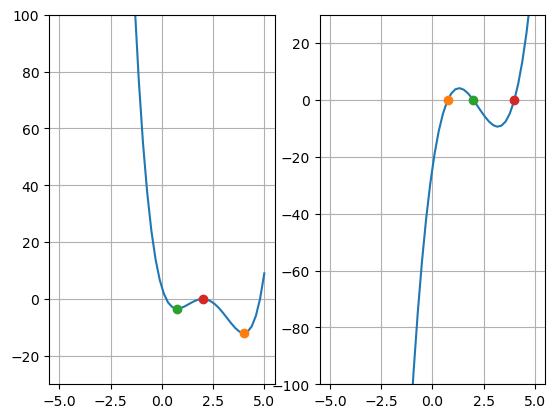

In [184]:
# define Eq. (1)

# use golden search to locate minimum

xs = np.linspace(-5,5)
zeroes = np.zeros(np.size(xs))


fig, (ax1, ax2) = plt.subplots(1, 2)

ax1.plot(xs, func_phi(xs))
ax1.plot(golden(func_phi, 0, 5), func_phi(golden(func_phi, 0, 5)),
        marker="o")
ax1.plot(golden(func_phi, -2, 2), func_phi(golden(func_phi, -2, 2)),
        marker="o")
ax1.plot(golden(neg_func_phi, 0, 4), func_phi(golden(neg_func_phi, 0, 4)),
        marker="o")
ax1.set_ylim(-30,100)


ax2.plot(xs, func_phi_prime(xs))
ax2.plot(bisection(0, 1, func_phi_prime), func_phi_prime(bisection(0, 1, func_phi_prime)),
        marker="o")
ax2.plot(bisection(1, 3, func_phi_prime), func_phi_prime(bisection(1, 3, func_phi_prime)),
        marker="o")
ax2.plot(bisection(3, 5, func_phi_prime), func_phi_prime(bisection(3, 5, func_phi_prime)),
        marker="o")

ax2.set_ylim(-100, 30)
ax1.grid()
ax2.grid()


plt.savefig("golden.png")
plt.show()
# report figure 1


#### Problem 1 code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
### Problem 2: Thomson problem with gradient descent ([Wikipedia link](https://en.wikipedia.org/wiki/Thomson_problem))

The goal of the Thomson problem is to determine the minimum electrostatic potential energy configuration given $N$ electrons constrained to the surface of a unit sphere. The electrons repel each other with a force given by Coulomb's law. The total electrostatic potential energy of each $N$-electron configuration may then be expressed as the sum of all pair-wise interaction energies:
$$ U(N) = \sum_{i<j} \frac{1}{r_{ij}}. \tag{2}$$
In context of minimization, we call Eq. $(2)$ our **cost function** or **loss function**. Here, we use simplified units of $e=1$ and $k=1/4\pi\epsilon_0=1$ (the Coulomb constant) without loss of generality.

- Complete the codes below. Add docstrings and comments to all functions.
- Create a 1D array `sphe_params` of initial particle positions in spherical coordinates (random $\theta$, $\phi$, BUT constrained to the surface of a unit sphere i.e. $r=1$).
- Minimize loss function $U(N)$ using gradient descent and `sphe_params` as your initial guess (see Section 3, you may the codes `termcrit`, `gradient`, and `descent` into your code below). Your output should be a 1D array similar to `sphe_params` but the positions that minimizes the potential.
- **[REPORT FIGURE 2]** Plot of $U$ vs $N$. Compare points calculated from gradient descent with the analytical $U_\text{thom}$ (see link in problem).
    - (Optional) Use 3D plotting in Matplotlib to show the geometry for $N=60$ configuration. What does it look like? What is its corresponding net electrostatic potential?

In [120]:
# add the `termcrit` function here
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)


# add the `gradient` function here
def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

    
# add the `descent` function here
def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews
    

# add docstrings and comments explaining what the functions do

In [121]:
# COMPLETE THIS FUNCTION
def spherical_to_cartesian(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)
    
    returns Nx3 array of particle positions in cartesian coords
    """
    N = len(sphe_params) // 2
    thetas = sphe_params[:N]
    phis = sphe_params[N:]
    
    x = np.sin(thetas)*np.cos(phis)
    y = np.sin(thetas)*np.sin(phis)
    z = np.cos(thetas)
    
    return np.column_stack((x, y, z))


def compute_dist(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns distance matrix where ij is the distance between ith and jth particle
    """
    pos = spherical_to_cartesian(sphe_params, R0)
    diff = pos[:, np.newaxis, :] - pos[np.newaxis, :, :]
    dist_matrix = np.linalg.norm(diff, axis=-1)
    return dist_matrix

def electrostatic_potential(sphe_params, R0=1.0):
    """
    sphe_params: Nx2 array of particle positions in spherical coords
    R0: radius set to 1 (unit circle)

    returns total electrostatic potential
    """
    # Guard: handle 2D matrix input passed from gradient()
    # if sphe_params.ndim == 2:
    #     return np.array([electrostatic_potential(sphe_params[:, j], R0) for j in range(sphe_params.shape[1])])

    d_matrix = compute_dist(sphe_params, R0)
    
    # calculate N dynamically from the input array length
    N_local = len(sphe_params) // 2
    i_upper, j_upper = np.triu_indices(N_local, k=1)
    distances = d_matrix[i_upper, j_upper]
        
    return np.sum(1.0 / distances)

In [170]:
# COMPLETE THIS CODE BLOCK

rng = np.random.default_rng(24601)
pi = np.pi

def rand(xa, xb, num):
    rand_cont = np.array([])
    for i in range(num):
        rs = rng.uniform(xa, xb)
        rand_cont = np.append(rand_cont, rs)
    return rand_cont

N =  60
init_theta =  rand(0, pi, N)
init_phi = rand(0, 2*pi, N)


xolds = np.hstack((init_theta, init_phi)) # this is the 1d array where the first half is the thetas and 2nd half is the phis

xnews = descent(electrostatic_potential, gradient, xolds)


#for i in range(100):
 #   xs = descent(electrostatic_potential, gradient, xs, gamma=0.01)
  #  print(electrostatic_potential(xs))

#  0.01, 500

xs = descent(electrostatic_potential, gradient, xolds, gamma=0.01, kmax=500)

print(electrostatic_potential(xs))
print(electrostatic_potential(xnews))

# use descent function and `xolds` to calculate the positions that minimizes the cost function
# you may need to test different gamma values (test diff values with your classmates to see which values are closest to theo)



Reached max iterations (200).
Reached max iterations (500).
3281.6735145153625
2200.102640142856


In [ ]:
# from N=2 up to 20 (or more), generate the optmized positions and calculate the corresponding minimized potential energies
# for each N, always initialize a random array of positions of N particles

# theoretical list of potential energies from N=2 to N=60
u_thom = [
    0.500000000, 1.732050808, 3.674234614, 6.474691495, 9.985281374,
    14.452977414, 19.675287861, 25.759986531, 32.716949460, 40.596450510,
    49.165253058, 58.853230612, 69.306363297, 80.670244114, 92.911655302,
    106.050404829, 120.084467447, 135.089467557, 150.881568334, 167.641622399,
    185.287536149, 203.930190663, 223.347074052, 243.812760299, 265.133326317,
    287.302615033, 310.491542358, 334.634439920, 359.603945904, 385.530838063,
    412.261274651, 440.204057448, 468.904853281, 498.569872491, 529.122408375,
    560.618887731, 593.038503566, 626.389009017, 660.675278835, 695.916744342,
    732.078107544, 769.190846459, 807.174263085, 846.188401061, 886.167113639,
    927.059270680, 968.713455344, 1011.557182654, 1055.182314726, 1099.819290319,
    1145.418964319, 1191.922290416, 1239.361474729, 1287.772720783, 1337.094945276,
    1387.383229253, 1438.618250640, 1490.773335279, 1543.830400976
] 

# REPORT FIGURE: generate a plot of U vs N 
# compare theoretical and those calculated from gradient descent
# add axes labels and legends

Reached max iterations (500).


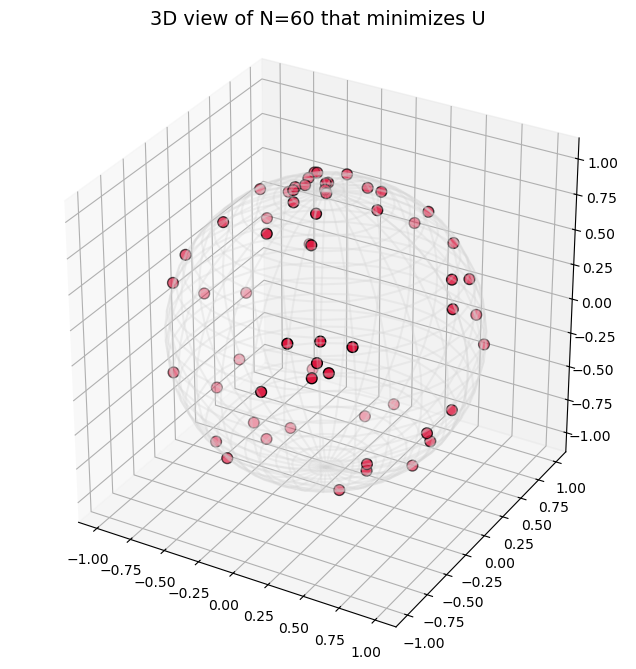

<Figure size 640x480 with 0 Axes>

In [178]:
# OPTIONAL
# for 3d plotting of N=60 (it might take a minute to process)

N = 60
init_theta = rand(0, pi, N) 
init_phi = rand(0, 2*pi, N) 
xolds = np.hstack((init_theta, init_phi))
xnews = descent(electrostatic_potential, gradient, xs, gamma=0.01, kmax=500)

# calculate the spherical coordinates of N particles that minimizes
pos = spherical_to_cartesian(xnews)
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')

# Draw wireframe sphere
u = np.linspace(0, 2 * np.pi, 30)
v = np.linspace(0, np.pi, 30)
x_sp = np.outer(np.cos(u), np.sin(v))
y_sp = np.outer(np.sin(u), np.sin(v))
z_sp = np.outer(np.ones(np.size(u)), np.cos(v))
ax.plot_wireframe(x_sp, y_sp, z_sp, color='lightgrey', alpha=0.3)

# Plot charge positions
ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color='crimson', s=60, edgecolors='k', depthshade=True)

ax.set_box_aspect([1, 1, 1])
ax.set_title('3D view of N=60 that minimizes U', fontsize=14)
plt.show()
plt.savefig("config.png")

#### Problem 2 code summary

Most of the difficulty of the problem was in figuring out how the stuff I was supposed to add would affect the functions that are already defined ahead of time. Its my first experience working in somebody else's code.

---
## Section 3: Notes

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Golden search (minimization tool)

In [2]:
from math import sqrt

def golden(phi, x0, x1, kmax=200, tol=1.e-8):
    varphi = 0.5*(1 + sqrt(5))
    
    for k in range(1,kmax):
        x2 = x0 + (x1-x0)/(varphi+1)
        x3 = x0 + (x1-x0)*varphi/(varphi+1)
        
        if phi(x3) < phi(x2):
            x0 = x2
        else:
            x1 = x3
    
        xnew = (x0+x1)/2
        xdiff = abs(x1-x0)
    
        if abs(xdiff) < tol:
            break
    else:
        xnew = None
    
    return xnew

#### Example: 

The Buckingham potential is an approximate representation of the potential
energy of interaction between atoms in a solid or gas as a function of the distance $r$ between them:
$$ V(r) = V_0 \left[\left(\frac{\sigma}{r}\right)^6 - e^{-r/\sigma}\right].$$

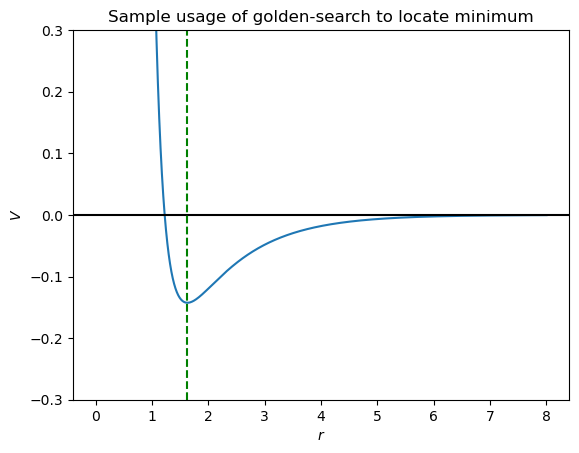

In [27]:
sigma = 1

def V(r, V0=1):
    return V0 * ((sigma / r)**6 - np.exp(-r/sigma))

rlist = np.linspace(1e-3, 8, 1000)
rmin = golden(V, 1.1, 2, kmax=200, tol=1e-8)
plt.plot(rlist, V(rlist))
plt.ylim(-.3, .3)
plt.axhline(0, c='k')
plt.axvline(rmin, c='g', ls='--')
plt.xlabel(r'$r$')
plt.ylabel(r'$V$')
plt.title('Sample usage of golden-search to locate minimum')
plt.show()

### Gradient descent (minimization tool)

In [20]:
def termcrit(xolds,xnews):
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def gradient(phi,xs,h=1.e-6):
    n = xs.size
    phi0 = phi(xs)
    Xph = (xs*np.ones((n,n))).T + np.identity(n)*h
    grad = (phi(Xph) - phi0)/h
    return grad

def descent(phi, gradient, xolds, gamma=0.15, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        grad = gradient(phi, xolds)
        xnews = xolds - gamma * grad
        err = termcrit(xolds, xnews)

        if err < tol:
            print(f"Converged at iteration {k}")
            return xnews
            
        xolds = np.copy(xnews)
        
    print(f"Reached max iterations ({kmax}).")
    return xnews

Converged at iteration 50


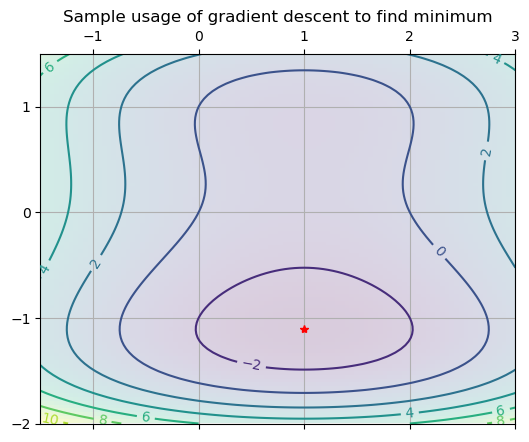

In [26]:
def sample_phi(xs):
    x0, x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x = np.linspace(-1.5, 3.0, 100)
y = np.linspace(-2, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = sample_phi(np.array([X, Y]))

xolds = np.array([2.,0.25])
xnews = descent(sample_phi, gradient, xolds)

fig, ax = plt.subplots(dpi=100)

my_extent = [min(x), max(x), min(y), max(y)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
ax.plot(*xnews, 'r*')
ax.set_title("Sample usage of gradient descent to find minimum")
csx = ax.contour(X, Y, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')


fig.show()

### Powell's algorithm (minimization tool)

In [29]:
def powell(phi,xolds,nreset=4,cycmax=200,tol=1.e-8):
    n = xolds.size
    for icyc in range(cycmax):
        xnews = np.copy(xolds)
    
        if icyc%nreset==0:
            U = np.identity(n)
        for k in range(n):
            ga = golden(lambda g: phi(xnews+g*U[:,k]),-10.,+10.)
            xnews += ga*U[:,k]
        U[:,:-1] = U[:,1:]
        U[:,-1] = xnews - xolds
        ga = golden(lambda g: phi(xolds+g*U[:,-1]),-10.,+10.)
        xolds += ga*U[:,-1]
        
        err = termcrit(xolds,xnews)
        # print(icyc, xnews, err, phi(xnews))
        if err < tol:
            break
    else:
        xnews = None
    return xnews

[ 1.00000002 -1.10715988]


Text(0.5, 1.0, "Sample usage of powell's algorithm to find minimum")

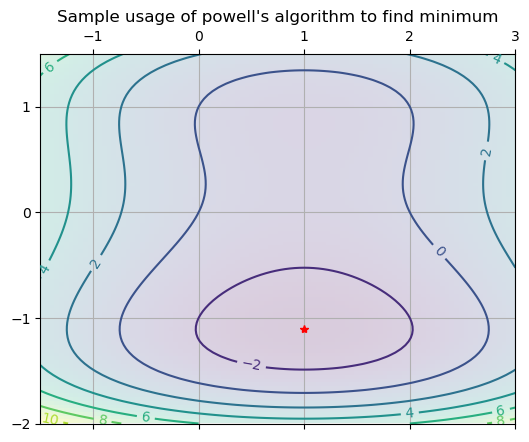

In [30]:
def phi_func(xs):
    x0,x1 = xs
    return x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1

x0 = np.linspace(-1.5, 3.0, 100)
x1 = np.linspace(-2, 1.5, 100)
X0, X1 = np.meshgrid(x, y)
output = phi_func(np.array([X0, X1]))

fig, ax = plt.subplots(1, 1, dpi=100)

xolds = np.array([2.,0.25])
xnews = powell(sample_phi, xolds); print(xnews)
ax.plot(*xnews, 'r*')

my_extent = [min(x0), max(x0), min(x1), max(x1)]
ax.matshow(output, origin="lower", extent=my_extent, alpha=0.2)
csx = ax.contour(X0, X1, output)
ax.clabel(csx)
ax.grid(True)
ax.set_aspect('equal')
ax.set_title("Sample usage of powell's algorithm to find minimum")

### Plotting subplots

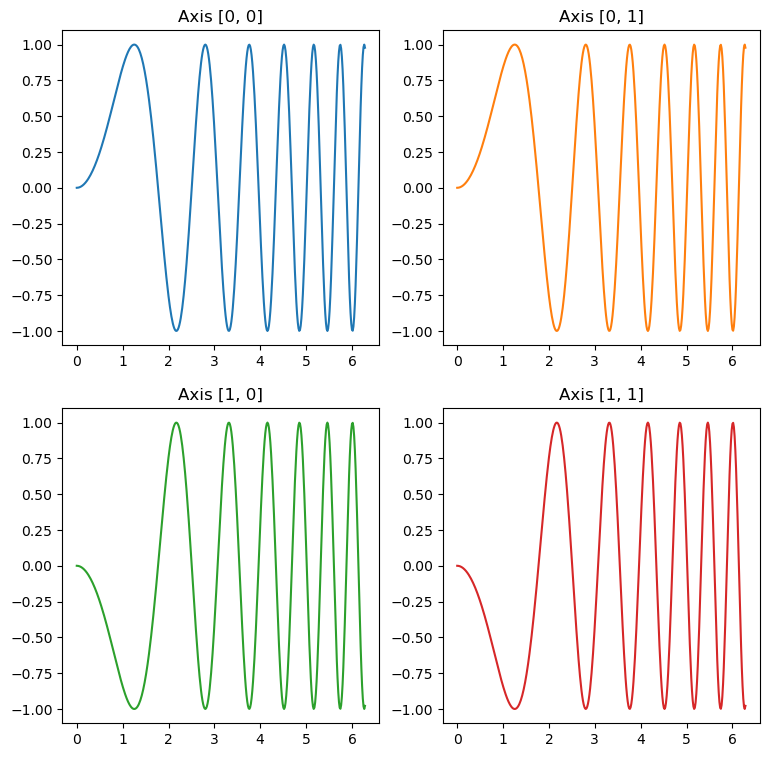

In [3]:
#sample incomplete 2 by 2 plot 

x = np.linspace(0, 2 * np.pi, 400)
y = np.sin(x ** 2)

fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x, y)
axs[0, 0].set_title('Axis [0, 0]')

axs[0, 1].plot(x, y, 'tab:orange')
axs[0, 1].set_title('Axis [0, 1]')

axs[1, 0].plot(x, -y, 'tab:green')
axs[1, 0].set_title('Axis [1, 0]')

axs[1, 1].plot(x, -y, 'tab:red')
axs[1, 1].set_title('Axis [1, 1]')

fig.show()

### Others

(Optional) Visualizing the vector field.
This is not required to get the method running, but it's a nice way for us to realize that we are indeed working with vector fields. Also, the mesh-forming syntax here will be useful for our succeeding activities.

In [7]:
def nonlin_func(x):
    # From Eq. 5.72 in Gezerlis, annotating Code 5.5
    #* Note: we expect the input and output of the function
    #  to be BOTH vectors. If x is a k-dimensional vector,
    #  then f(x) should also return a k-dimensional vector.  
    x0, x1 = x[0], x[1]

    # This is the same as defining f0 and f1 separately. We
    # just casted the output directly into the array
    return np.array([
        (x0**2) - (2*x0) + (x1**4) - (2*x1**2) + (x1),
        (x0**2) + (x0) + (2*x1**3) - (2*x1**2) - (1.5*x1) - 0.05   
    ])

x_test = np.array([0.5, 0.6])
print(nonlin_func(x_test))

[-0.7404 -0.488 ]


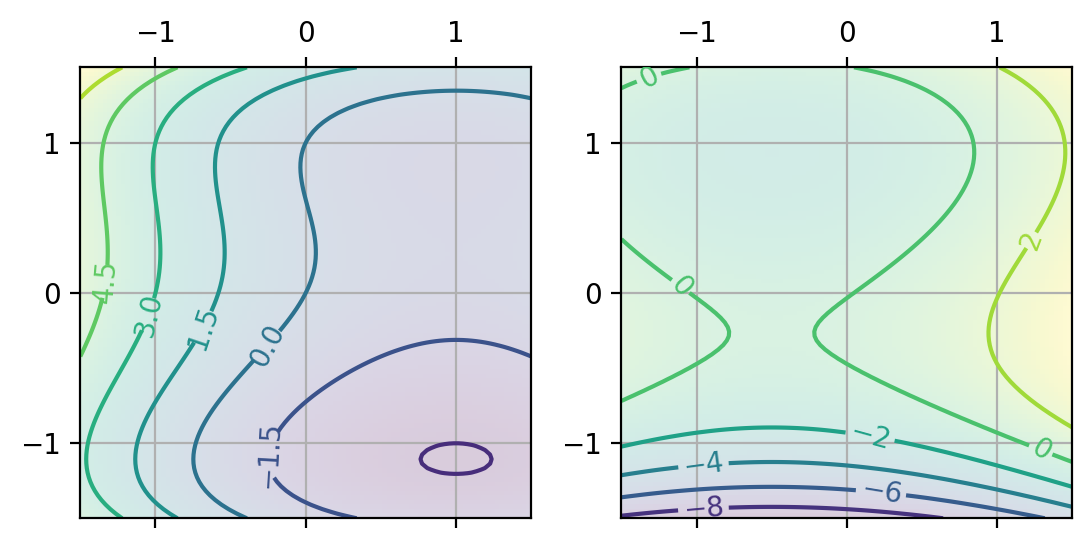

In [19]:
x = np.linspace(-1.5, 1.5, 100)
y = np.linspace(-1.5, 1.5, 100)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, axs = plt.subplots(1, 2, dpi=200)

my_extent = [min(x), max(x), min(y), max(y)]
axs[0].matshow(output[0], origin="lower", extent=my_extent, alpha=0.2)
csx = axs[0].contour(X, Y, output[0])
axs[0].clabel(csx)

axs[1].matshow(output[1], origin="lower", extent=my_extent, alpha=0.2)
csy = axs[1].contour(X, Y, output[1])
axs[1].clabel(csy)

for ax in axs:
    ax.grid(True)

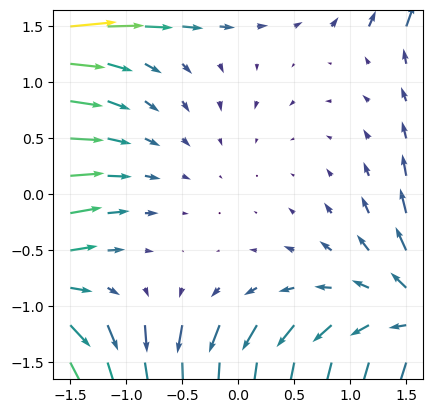

In [9]:
x = np.linspace(-1.5, 1.5, 10)
y = np.linspace(-1.5, 1.5, 10)
X, Y = np.meshgrid(x, y)
output = nonlin_func(np.array([X, Y]))

fig, ax = plt.subplots(1, dpi=100)

mag = np.sqrt(output[0]**2 + np.sqrt(output[1]**2))
ax.quiver(X, Y, output[0], output[1], mag)
ax.grid(alpha=0.2)
ax.set_aspect("equal")

In [11]:
import numpy as np

def backsub(U,bs):
    """
    Input:
        * U matrix
        * bs known vector
    Output: solve column vector using back substitution
    """
    n = bs.size
    xs = np.zeros(n)
    for i in reversed(range(n)):
        xs[i] = (bs[i] - U[i,i+1:]@xs[i+1:])/U[i,i]
    return xs

def gauelimpivot(inA,inbs):
    """
    Input:
        * inA matrix
        * inbs known vector
    Output: solve column vector with gaussian elimination
    """
    A = np.copy(inA)
    bs = np.copy(inbs)
    n = bs.size
    for j in range(n-1):
        k = np.argmax(np.abs(A[j:,j])) + j
        if k != j:
            A[j,:], A[k,:] = A[k,:], A[j,:].copy()
            bs[j], bs[k] = bs[k], bs[j]
    
        for i in range(j+1,n):
            coeff = A[i,j]/A[j,j]
            A[i,j:] -= coeff*A[j,j:]
            bs[i] -= coeff*bs[j]
            
    xs = backsub(A,bs)
    return xs

def termcrit(xolds,xnews):
    """
    Input:
        * xolds older estimates
        * xnews newest estimates
    Output: solve termination criterion with numpy
    """
    errs = np.abs((xnews - xolds)/xnews)
    return np.sum(errs)

def fs(xs):
    """
    Input:
        * xs tuple input
    Output: scalar outputs from two functions given one set of input
    """
    x0, x1 = xs
    f0 = x0**2 - 2*x0 + x1**4 - 2*x1**2 + x1
    f1 = x0**2 + x0 + 2*x1**3 - 2*x1**2 - 1.5*x1 - 0.05
    return np.array([f0,f1])

def jacobian(fs,xs,h=1.e-4):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * xs : 1d array representing the eval point
        * h : float, optional 
    
    Output: builds jacobian matrix Jf and array containing values evaluated at xs
    """
    n = xs.size
    iden = np.identity(n)
    Jf = np.zeros((n,n))
    fs0 = fs(xs)
    for j in range(n):
        fs1 = fs(xs+iden[:,j]*h)
        Jf[:,j] = (fs1 - fs0)/h
    return Jf, fs0

def multinewton(fs,jacobian,xolds,kmax=200,tol=1.e-8):
    """
    Input:
        * fs : function of system of equations taking 1d array `xs` and returns 1d array of func values
        * jacobian : calcs the jacobian
        * xolds : 1d array containing the initial guess vector
        * kmax : no of iterations
        * tol : tolerance for convergence
    
    Output: 1d array of the approximate root vector if converged
    """
    for k in range(1,kmax):
        Jf, fsxolds = jacobian(fs, xolds)
        xnews = xolds + gauelimpivot(Jf, -fsxolds)
        err = termcrit(xolds, xnews)
        print(k, xnews, err)
        if err < tol:
            break
        
        xolds = np.copy(xnews)
    else:
        xnews = None
    return xnews

if __name__ == '__main__':
    xolds = np.array([1.,1.])
    xnews = multinewton(fs, jacobian, xolds)
    print(xnews); print(fs(xnews))

1 [0.68327197 1.99963178] 0.9634539886260238
2 [0.38286992 1.62816875] 1.0127537609121247
3 [0.56358881 1.4144802 ] 0.4717294772974023
4 [0.5900614  1.32693341] 0.11084089956296016
5 [0.59215596 1.3126421 ] 0.014424613090514531
6 [0.59218625 1.31228241] 0.00032525133774643014
7 [0.59218627 1.31228212] 2.5249741194196077e-07
8 [0.59218627 1.31228212] 4.335881037833639e-11
[0.59218627 1.31228212]
[3.97459843e-14 2.77972090e-14]
